In [1]:
import json
import os
from pathlib import Path
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy import stats

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['STIXGeneral']
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['pdf.fonttype'] = 42

# Run notebook from analysis/ or set explicitly; path relative to cwd
RESULTS_DIR = (Path("..") / "results").resolve()

# Map full model paths to simplified names (like configs: dinov2_14, clip_16, etc.)
def simplify_model_name(full_name):
    """Convert e.g. facebook/dinov2-base -> dinov2_14, openai/clip-vit-base-patch32 -> clip_32"""
    m = full_name.lower()
    if "dinov2" in m or "dinov2-base" in m:
        return "DINOv2"
    if "dino-vitb" in m:
        return "DINO"
    if "vit-mae" in m or "mae" in m:
        return "MAE"
    if "google" in m:
        if "patch32" in m or "patch 32" in m:
            return "ImageNet 32"
        return "ImageNet 16"
    if "clip" in m:
        if "patch32" in m or "patch 32" in m:
            return "CLIP 32"
        return "CLIP 16"
    return full_name.replace("/", "_")


def load_gestalt_results(results_dir=None, json_filename="gestalt_eval.json"):
    """
    Load all *_gestalt_eval.json files from the results directory.
    Returns: dict[model_name, dict[layer, results_dict]]
    """
    results_dir = Path(results_dir or RESULTS_DIR)
    data = defaultdict(dict)
    
    for org_dir in Path(results_dir).iterdir():
        if not org_dir.is_dir():
            continue
        for model_dir in org_dir.iterdir():
            if not model_dir.is_dir():
                continue
            model_name = f"{org_dir.name}/{model_dir.name}"
            for layer_dir in model_dir.iterdir():
                if not layer_dir.is_dir():
                    continue
                try:
                    layer = int(layer_dir.name)
                except ValueError:
                    continue
                json_path = layer_dir / json_filename
                if json_path.exists():
                    with open(json_path, "r") as f:
                        data[model_name][layer] = json.load(f)
    
    return dict(data)


def plot_per_layer_accuracy(data=None, results_dir=None, models=None, subplots_per_model=True, ax=None):
    """
    Plot per-layer test accuracy for each model, compared to orientation and location accuracies.
    
    For each model: x=layer, y=accuracy; lines for base (test), orientation, location.
    subplots_per_model: if True, one subplot per model; else all models on one plot.
    """
    data = data or load_gestalt_results(results_dir)
    if models:
        data = {m: data[m] for m in models if m in data}
    
    model_list = sorted(data.items())
    n = len(model_list)
    
    if subplots_per_model and n > 1:
        ncols = min(n, 3)
        nrows = (n + ncols - 1) // ncols
        fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), squeeze=False)
        axes = axes.flatten()
        for idx in range(n, len(axes)):
            axes[idx].set_visible(False)
    else:
        if ax is not None:
            fig = ax.figure
            axes = [ax]
        else:
            fig, ax = plt.subplots(figsize=(10, 6))
            axes = [ax]
    
    for idx, (model_name, layer_results) in enumerate(model_list):
        a = axes[idx] if subplots_per_model and n > 1 else axes[0]
        layers = sorted(layer_results.keys())
        base_acc = [layer_results[l]["standard"]["base"]["accuracy"] for l in layers]
        orient_acc = [layer_results[l]["standard"]["orientation"]["accuracy"] for l in layers]
        loc_acc = [layer_results[l]["standard"]["location"]["accuracy"] for l in layers]
        
        suff = f" ({model_name})" if not (subplots_per_model and n > 1) else ""
        a.plot(layers, base_acc, "o-", label=f"Test/base{suff}", linewidth=2, markersize=6)
        a.plot(layers, orient_acc, "s--", label=f"Orientation{suff}", alpha=0.8, markersize=4)
        a.plot(layers, loc_acc, "^-.", label=f"Location{suff}", alpha=0.8, markersize=4)
        
        a.set_xlabel("Layer")
        a.set_ylabel("Accuracy")
        if subplots_per_model and n > 1:
            short_name = simplify_model_name(model_name)
            a.set_title(short_name)
        else:
            a.set_title("Per-layer probe accuracy vs. orientation and location controls")
        a.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
        a.grid(True, alpha=0.3)
        a.axhline(0.5, color="gray", linestyle=":", alpha=0.5)
    
    plt.tight_layout()
    return axes[0] if len(axes) == 1 else axes


def plot_ablation_decrement_by_layer(data=None, results_dir=None, models=None, control_band="iqr", normalize_by="max", ax=None):
    """
    One subplot per model. X=layer, Y=ablation decrement (optionally normalized).
    Control band is dynamic per (model, layer): shows distribution of control decrements at that layer.
    control_band: "std", "iqr", or "minmax"
    normalize_by: "max" | "mean" | None. If set, y is divided by (base - max/mean of location, orientation) for that layer.
    """
    data = data or load_gestalt_results(results_dir)
    if models:
        data = {m: data[m] for m in models if m in data}

    model_list = sorted(data.items())
    n = len(model_list)
    ncols = min(n, 3)
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), squeeze=False)
    axes = axes.flatten()
    for idx in range(n, len(axes)):
        axes[idx].set_visible(False)

    for idx, (model_name, layer_results) in enumerate(model_list):
        ax = axes[idx]
        short_name = simplify_model_name(model_name)
        layers = sorted(layer_results.keys())
        decs = []
        control_lower, control_upper = [], []

        for l in layers:
            res = layer_results[l]
            base = res["standard"]["base"]["accuracy"]
            orient = res["standard"]["orientation"]["accuracy"]
            loc = res["standard"]["location"]["accuracy"]
            abl = res["ablation"]["base"]["accuracy"]
            dec = base - abl

            if normalize_by == "max":
                denom = base - max(orient, loc)
            elif normalize_by == "mean":
                denom = base - (orient + loc) / 2
            else:
                denom = 1.0

            denom = max(denom, 1e-6)
            dec_norm = dec / denom
            decs.append(dec_norm)

            ctrl_decs = [base - c for c in res["controls"]["base"]["accuracy"]]
            if control_band == "std":
                m, s = np.mean(ctrl_decs), np.std(ctrl_decs)
                lo, hi = (m - s) / denom, (m + s) / denom
            elif control_band == "iqr":
                q25, q75 = np.percentile(ctrl_decs, [25, 75])
                lo, hi = q25 / denom, q75 / denom
            else:
                lo, hi = np.min(ctrl_decs) / denom, np.max(ctrl_decs) / denom
            control_lower.append(lo)
            control_upper.append(hi)

        ax.fill_between(layers, control_lower, control_upper, alpha=0.2, color="gray", label="Control ablations")
        ax.plot(layers, decs, "o-", color="C0", linewidth=2, markersize=6, label="Target ablation")
        ax.set_xlabel("Layer")
        ylabel = "Ablation decrement"
        if normalize_by:
            ylabel += f" / (base − {normalize_by}(loc, orient))"
        ax.set_ylabel(ylabel)
        ax.set_title(short_name)
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)
        ax.axhline(0, color="gray", linestyle=":", alpha=0.5)

    plt.tight_layout()
    return axes

In [5]:
# Example usage:
from typing import Any

results_path = Path("../results")

data = load_gestalt_results(results_path, json_filename="gestalt_eval.json")
curves_data = load_gestalt_results(results_path, json_filename="curves_gestalt_eval.json")

print("Models:", list[Any](data.keys()))
print("Layers per model:", {m: sorted(d.keys()) for m, d in data.items()})

Models: ['facebook/dino-vitb16', 'facebook/dinov2-base', 'facebook/vit-mae-base', 'google/vit-base-patch16-224-in21k', 'google/vit-base-patch32-224-in21k', 'openai/clip-vit-base-patch16', 'openai/clip-vit-base-patch32']
Layers per model: {'facebook/dino-vitb16': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'facebook/dinov2-base': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'facebook/vit-mae-base': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'google/vit-base-patch16-224-in21k': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'google/vit-base-patch32-224-in21k': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'openai/clip-vit-base-patch16': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'openai/clip-vit-base-patch32': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]}


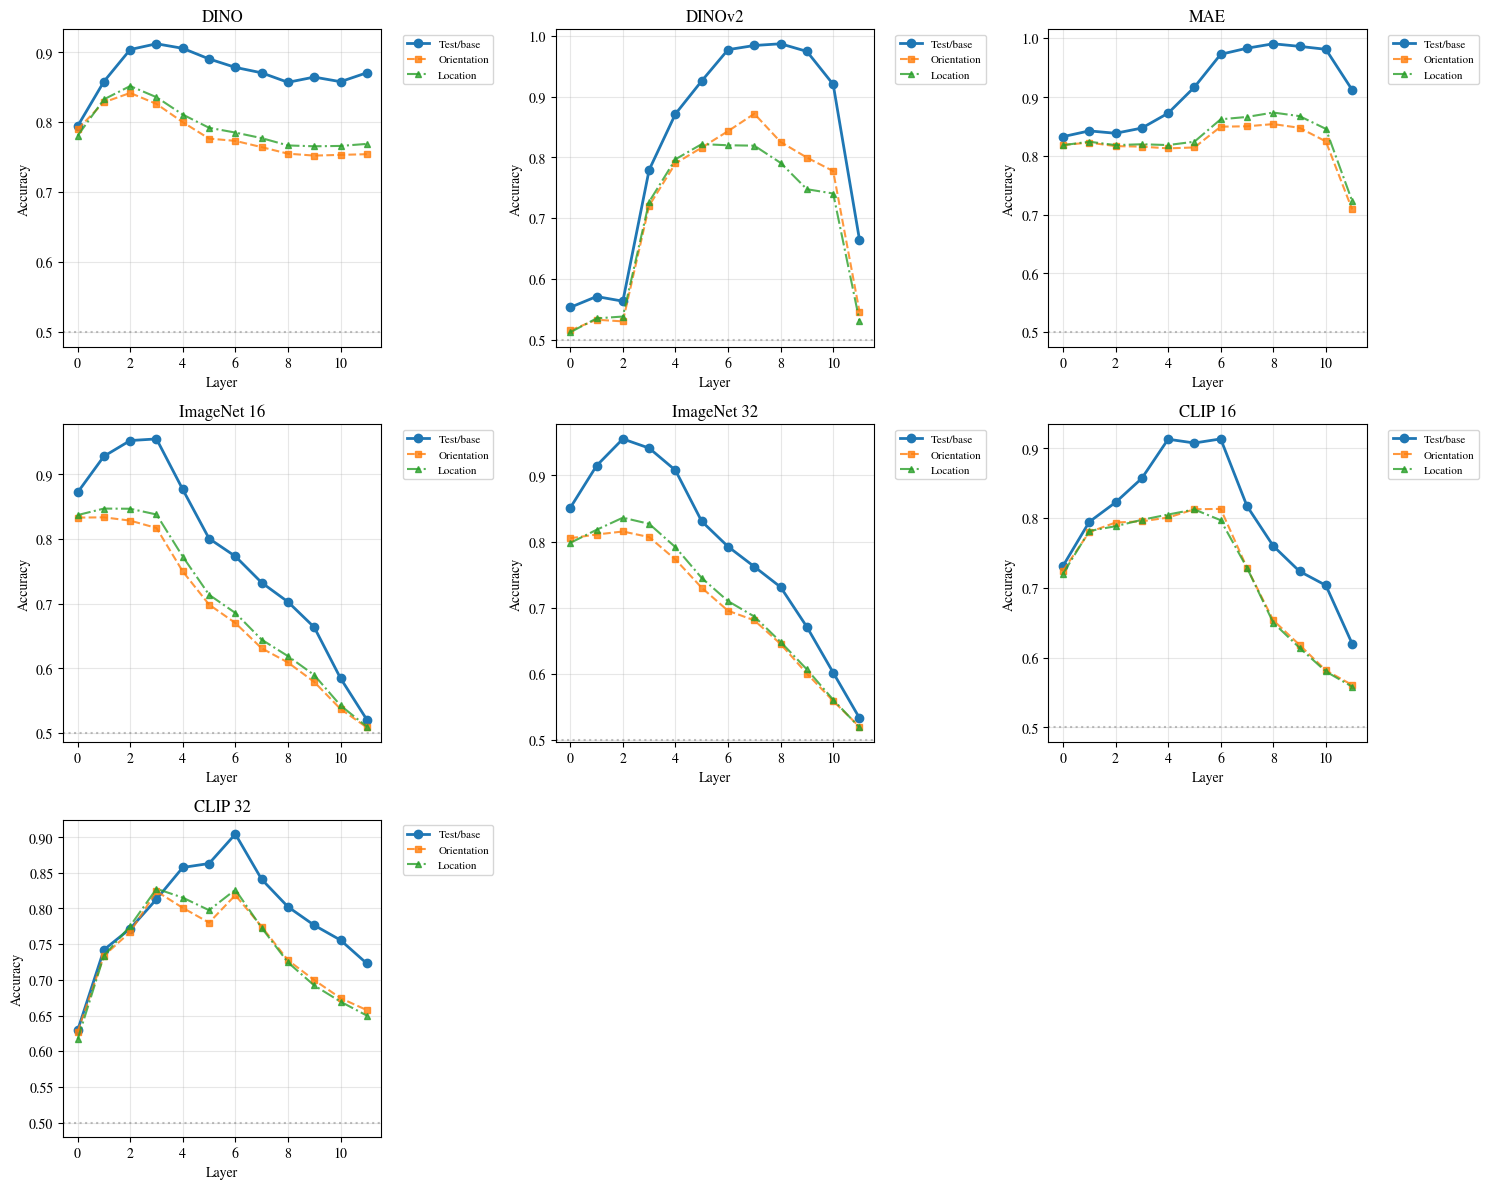

In [6]:
# Plot 1: Per-layer test accuracy vs orientation and location
plot_per_layer_accuracy(data=data)
plt.show()

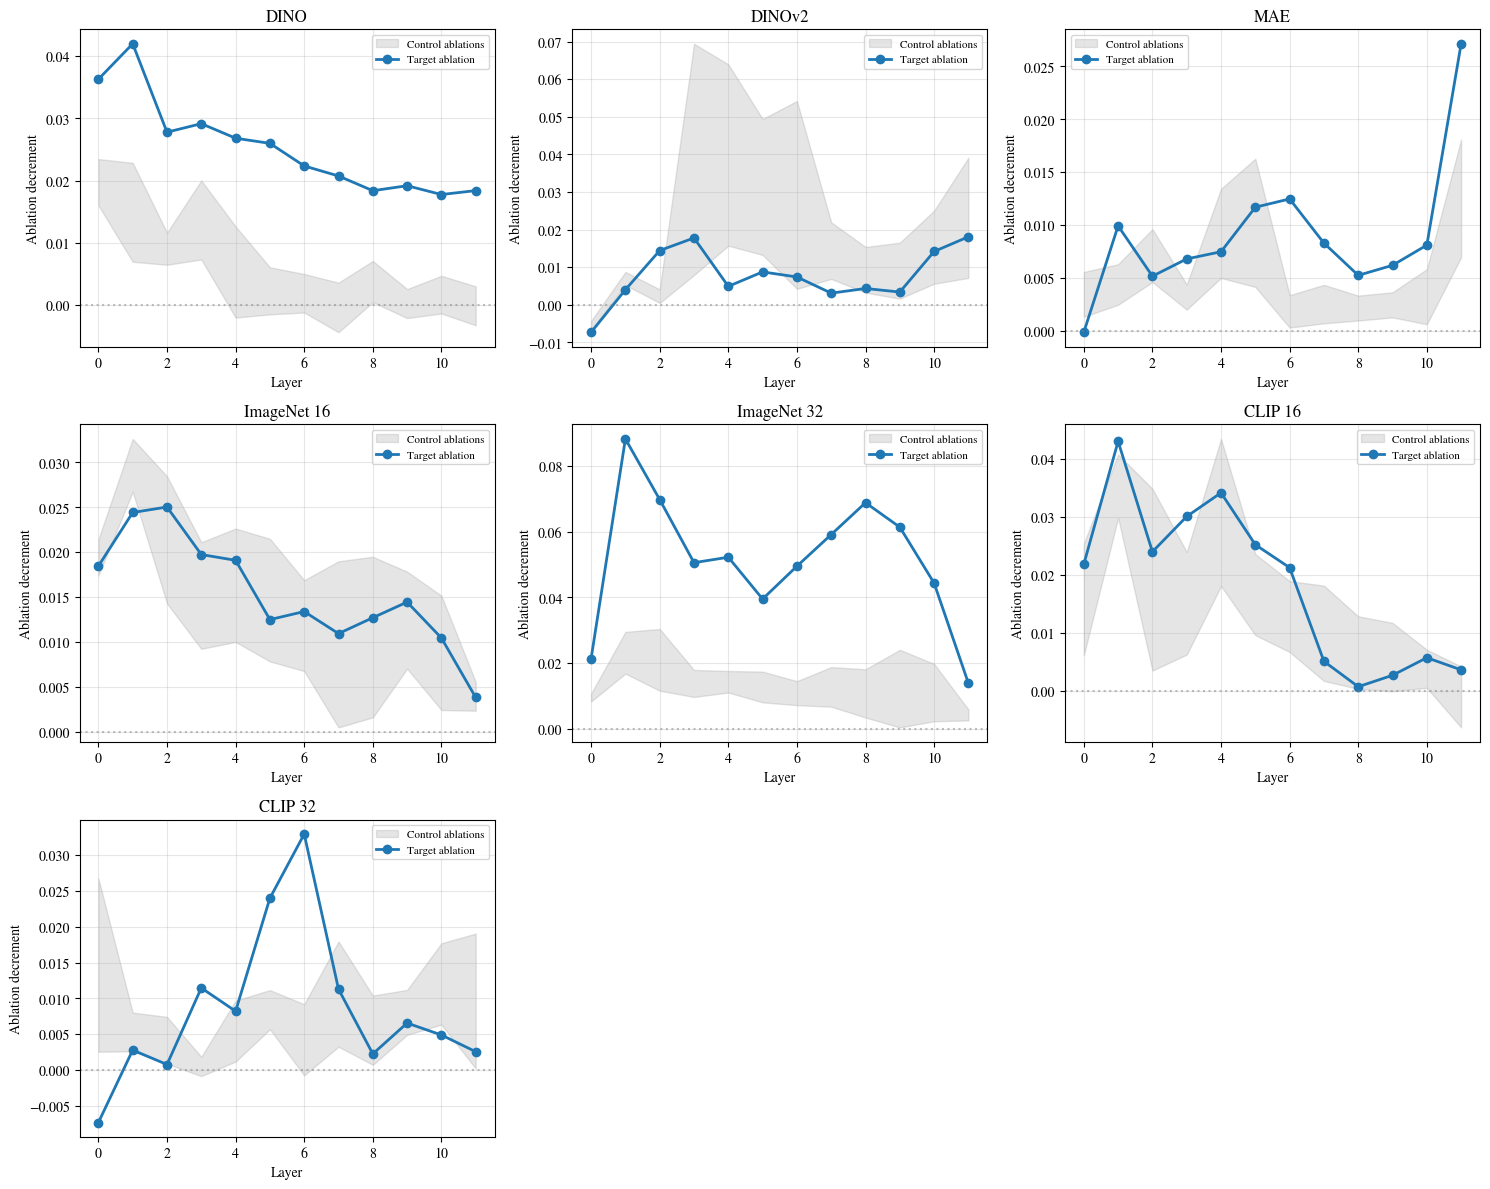

In [8]:
# Plot 2: Ablation decrement by layer (one subplot per model, dynamic control bands per layer)
plot_ablation_decrement_by_layer(data=data, control_band="iqr", normalize_by=None)
plt.show()

In [26]:
def plot_average_scramble_delta_by_layer(data=None, results_dir=None, models=None, ax=None, figsize=(7, 5)):
    """
    Plot per-layer delta across models, where
    delta(layer, model) = base_accuracy - max(orientation_accuracy, location_accuracy).

    Main line: mean delta across models.
    Shaded band: min-to-max delta across models at each layer.
    """
    data = data or load_gestalt_results(results_dir)
    if models:
        data = {m: data[m] for m in models if m in data}

    if not data:
        raise ValueError('No model data available for plotting.')

    deltas_by_model = {}
    all_layers = set()

    for model_name, layer_results in sorted(data.items()):
        model_deltas = {}
        for layer in sorted(layer_results.keys()):
            res = layer_results[layer]["standard"]
            base = res["base"]["accuracy"]
            orient = res["orientation"]["accuracy"]
            loc = res["location"]["accuracy"]
            model_deltas[layer] = base - max(orient, loc)
            all_layers.add(layer)
        deltas_by_model[model_name] = model_deltas

    layers = sorted(all_layers)
    delta_matrix = []
    for model_name in sorted(deltas_by_model.keys()):
        row = [deltas_by_model[model_name].get(layer, np.nan) for layer in layers]
        delta_matrix.append(row)

    delta_matrix = np.asarray(delta_matrix, dtype=float)
    mean_delta = np.nanmean(delta_matrix, axis=0)
    min_delta = np.nanmin(delta_matrix, axis=0)
    max_delta = np.nanmax(delta_matrix, axis=0)

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)

    ax.fill_between(
        layers,
        min_delta,
        max_delta,
        color="#4169E1",
        alpha=0.18,
        label="Model range (min, max)",
    )
    ax.plot(layers, mean_delta, "o-", color="#4169E1", linewidth=2.5, markersize=6, label=r"Mean $\Delta$")

    def multiply_by_ten(tick_value, position):
        # tick_value is the actual data value at the tick position (e.g., 0, 20, 40)
        # position is the index of the tick
        new_value = tick_value * 100
        return f'{new_value:.1f}' # Format as a string with no decimals

    # 2. Apply the formatter to the y-axis
    # The FuncFormatter maps the original tick values to the new multiplied labels
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(multiply_by_ten))

    ax.set_xlabel("Layer", fontsize=13)
    ax.set_ylabel(r"$\Delta$ Probe Test Accuracy (Base $-$ Scrambled)", fontsize=13)
    ax.set_title(r"$\Delta$ Probe Test Accuracy (Base $-$ Scrambled) Across Layers", fontsize=15)
    ax.grid(True, alpha=0.3)
    ax.axhline(0, color="gray", linestyle=":", alpha=0.5)
    ax.legend(fontsize=15)

    plt.tight_layout()
    return fig


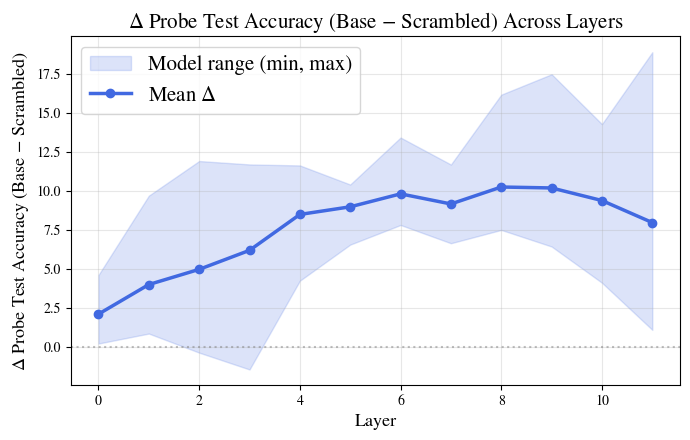

In [27]:
# Plot 3: Mean per-layer scramble delta with across-model min/max band
fig = plot_average_scramble_delta_by_layer(data=data, figsize=(7, 4.5))
plt.show()
fig.savefig(
    "../../figs/probe_deltas.pdf",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.1,
    transparent=True,  # no background fill
    format="pdf"
)

In [2]:
def build_max_probe_accuracy_latex_table(data=None, results_dir=None, models=None):
    """
    Build a LaTeX table with columns:
      Model | Max Probe Test Acc. (Base, Scrambled)
    where Scrambled is max over orientation/location at each layer, then max over layers.
    """
    data = data or load_gestalt_results(results_dir)
    if models:
        data = {m: data[m] for m in models if m in data}

    if not data:
        raise ValueError('No model data available for table.')

    rows = []
    for model_name, layer_results in sorted(data.items()):
        layers = sorted(layer_results.keys())
        base_vals = [layer_results[l]["standard"]["base"]["accuracy"] for l in layers]
        scrambled_vals = [
            max(
                layer_results[l]["standard"]["orientation"]["accuracy"],
                layer_results[l]["standard"]["location"]["accuracy"],
            )
            for l in layers
        ]

        max_base = max(base_vals) * 100.0
        max_scrambled = max(scrambled_vals) * 100.0
        rows.append((simplify_model_name(model_name), max_base, max_scrambled))

    lines = []
    lines.append(r'\begin{table}[t]')
    lines.append(r'\centering')
    lines.append(r'\begin{tabular}{lcc}')
    lines.append(r'\toprule')
    lines.append(r'Model & \multicolumn{2}{c}{Max Probe Test Acc.} \\')
    lines.append(r' & Base & Scrambled \\')
    lines.append(r'\midrule')

    for model_label, max_base, max_scrambled in rows:
        lines.append(f'{model_label} & {max_base:.1f}\% & {max_scrambled:.1f}\% \\')

    lines.append(r'\bottomrule')
    lines.append(r'\end{tabular}')
    lines.append(r'\caption{Maximum probe test accuracy by model for base and scrambled conditions.}')
    lines.append(r'\label{tab:max_probe_test_acc}')
    lines.append(r'\end{table}')

    return '\n'.join(lines)


SyntaxError: unterminated string literal (detected at line 35); perhaps you escaped the end quote? (2217520100.py, line 35)

In [ ]:
# Plot/Table 4: LaTeX table for max base vs scrambled probe test accuracy
latex_table = build_max_probe_accuracy_latex_table(data=data)
print(latex_table)


In [9]:
def plot_max_ablation_decrement_bar(data=None, results_dir=None, models=None, ax=None):
    """
    Single grouped bar chart by model:
      - Max target ablation decrement across layers
      - 75th percentile control ablation decrement at the target-max layer
    Decrement is defined as (base accuracy - ablated/control accuracy).
    """
    data = data or load_gestalt_results(results_dir)
    if models:
        data = {m: data[m] for m in models if m in data}

    if not data:
        raise ValueError('No model data available for plotting.')

    model_names = []
    max_target = []
    p75_control = []

    for model_name, layer_results in sorted(data.items()):
        best_target_dec = -np.inf
        best_layer_ctrl_decs = []

        for layer in sorted(layer_results.keys()):
            res = layer_results[layer]
            base = res['standard']['base']['accuracy']

            target_acc = res['ablation']['base']['accuracy']
            target_dec = base - target_acc

            if target_dec > best_target_dec:
                best_target_dec = target_dec
                ctrl_accs = res['controls']['base']['accuracy']
                best_layer_ctrl_decs = [base - c for c in ctrl_accs]

        model_names.append(simplify_model_name(model_name))
        max_target.append(best_target_dec if best_target_dec > -np.inf else np.nan)
        p75_control.append(
            float(np.percentile(best_layer_ctrl_decs, 75)) if best_layer_ctrl_decs else np.nan
        )

    if ax is None:
        fig, ax = plt.subplots(figsize=(11, 5))

    x = np.arange(len(model_names))
    width = 0.38

    ax.bar(x - width / 2, max_target, width=width, color='#4169E1', label='Target ablation (max)')
    ax.bar(
        x + width / 2,
        p75_control,
        width=width,
        color='lightgray',
        label='Control ablation (75th pct @ target-max layer)',
    )

    ax.set_xticks(x)
    ax.set_xticklabels(model_names, ha='center', fontsize=12)
    ax.set_ylabel('Ablation decrement')
    ax.set_title('Max target vs layer-matched 75th percentile control ablation decrement by model')
    ax.grid(True, axis='y', alpha=0.3)
    ax.legend()

    plt.tight_layout()
    return fig


def _has_decrement_by_dataset(res):
    """Check if results have ablation/controls on orientation and location (required for selectivity plots)."""
    return ("ablation" in res and "location" in res["ablation"] and "orientation" in res["ablation"]
            and "controls" in res and "location" in res["controls"] and "orientation" in res["controls"])


def plot_ablation_decrement_by_dataset(data=None, results_dir=None, models=None, ax=None):
    """
    Bar plot of ablation performance decrement on Object (base), Orientation, and Location datasets.
    Uses the layer with maximum Object decrement per model.
    Requires ablation results on all three datasets (e.g. curves_gestalt_eval.json).
    """
    data = data or load_gestalt_results(results_dir)
    if models:
        data = {m: data[m] for m in models if m in data}
    if not data:
        raise ValueError("No model data available.")
    model_names = []
    obj_decs, orient_decs, loc_decs = [], [], []
    for model_name, layer_results in sorted(data.items()):
        peak_layer = None
        best_obj_dec = -np.inf
        oo, oo_orient, oo_loc = np.nan, np.nan, np.nan
        for layer in sorted(layer_results.keys()):
            res = layer_results[layer]
            if not _has_decrement_by_dataset(res):
                continue
            base = res["standard"]["base"]["accuracy"]
            orient = res["standard"]["orientation"]["accuracy"]
            loc = res["standard"]["location"]["accuracy"]
            obj_dec = base - res["ablation"]["base"]["accuracy"]
            if obj_dec > best_obj_dec:
                best_obj_dec = obj_dec
                peak_layer = layer
                oo = obj_dec
                oo_orient = orient - res["ablation"]["orientation"]["accuracy"]
                oo_loc = loc - res["ablation"]["location"]["accuracy"]
        model_names.append(simplify_model_name(model_name))
        obj_decs.append(oo)
        orient_decs.append(oo_orient)
        loc_decs.append(oo_loc)
    if ax is None:
        fig, ax = plt.subplots(figsize=(11, 5))
    x = np.arange(len(model_names))
    w = 0.25
    ax.bar(x - w, obj_decs, width=w, label="Object", color="#4169E1")
    ax.bar(x, orient_decs, width=w, label="Orientation", color="#E16941")
    ax.bar(x + w, loc_decs, width=w, label="Location", color="#69E141")
    ax.set_xticks(x)
    ax.set_xticklabels(model_names, ha="center", fontsize=12)
    ax.set_ylabel("Ablation decrement")
    ax.set_title("Ablation decrement by dataset (peak Object-decrement layer)")
    ax.legend()
    ax.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    return ax.figure


def plot_ablation_selectivity_bar(data=None, results_dir=None, models=None, control_band="iqr", ax=None):
    """
    Bar chart of ablation selectivity: (decrement on base) - max(decrement on orient, decrement on loc).
    Target ablation vs control ablations, with control_band: "std", "iqr", or "minmax".
    Uses peak Object-decrement layer per model.
    Requires ablation/controls on all three datasets (e.g. curves_gestalt_eval.json).
    """
    data = data or load_gestalt_results(results_dir)
    if models:
        data = {m: data[m] for m in models if m in data}
    if not data:
        raise ValueError("No model data available.")
    model_names = []
    target_sel, ctrl_center, ctrl_lower, ctrl_upper = [], [], [], []
    for model_name, layer_results in sorted(data.items()):
        best_obj_dec = -np.inf
        best_sel, best_ctrl_sels = np.nan, []
        for layer in sorted(layer_results.keys()):
            res = layer_results[layer]
            if not _has_decrement_by_dataset(res):
                continue
            base = res["standard"]["base"]["accuracy"]
            orient = res["standard"]["orientation"]["accuracy"]
            loc = res["standard"]["location"]["accuracy"]
            obj_dec = base - res["ablation"]["base"]["accuracy"]
            orient_dec = orient - res["ablation"]["orientation"]["accuracy"]
            loc_dec = loc - res["ablation"]["location"]["accuracy"]
            sel = obj_dec - max(orient_dec, loc_dec)
            ctrl_base = res["controls"]["base"]["accuracy"]
            ctrl_orient = res["controls"]["orientation"]["accuracy"]
            ctrl_loc = res["controls"]["location"]["accuracy"]
            ctrl_sels = [(base - cb) - max((orient - co), (loc - cl))
                         for cb, co, cl in zip(ctrl_base, ctrl_orient, ctrl_loc)]
            if obj_dec > best_obj_dec and ctrl_sels:
                best_obj_dec = obj_dec
                best_sel = sel
                best_ctrl_sels = ctrl_sels
        model_names.append(simplify_model_name(model_name))
        target_sel.append(best_sel)
        if best_ctrl_sels:
            arr = np.array(best_ctrl_sels)
            if control_band == "std":
                m, s = np.mean(arr), np.std(arr)
                ctrl_center.append(float(m))
                ctrl_lower.append(float(m - s))
                ctrl_upper.append(float(m + s))
            elif control_band == "iqr":
                q25, med, q75 = np.percentile(arr, [25, 50, 75])
                ctrl_center.append(float(med))
                ctrl_lower.append(float(q25))
                ctrl_upper.append(float(q75))
            else:  # minmax
                ctrl_center.append(float(np.percentile(arr, 75)))
                ctrl_lower.append(float(np.min(arr)))
                ctrl_upper.append(float(np.max(arr)))
        else:
            ctrl_center.append(np.nan)
            ctrl_lower.append(np.nan)
            ctrl_upper.append(np.nan)
    if ax is None:
        fig, ax = plt.subplots(figsize=(11, 5))
    x = np.arange(len(model_names))
    w = 0.38
    ax.bar(x - w/2, target_sel, width=w, color="#4169E1", label="Target ablation")
    ctrl_center = np.array(ctrl_center)
    ctrl_lower = np.array(ctrl_lower)
    ctrl_upper = np.array(ctrl_upper)
    ax.bar(x + w/2, ctrl_center, width=w, color="lightgray", label=f"Control ablation ({control_band})")
    err_lo = ctrl_center - ctrl_lower
    err_hi = ctrl_upper - ctrl_center
    ax.errorbar(x + w/2, ctrl_center, yerr=[err_lo, err_hi], fmt="none", color="gray", capsize=3)
    ax.set_xticks(x)
    ax.set_xticklabels(model_names, ha="center", fontsize=12)
    ax.set_ylabel("Selectivity (Object dec − max(Orient dec, Loc dec))")
    ax.set_title(f"Ablation selectivity by model (control band: {control_band})")
    ax.axhline(0, color="gray", linestyle=":", alpha=0.5)
    ax.legend()
    ax.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    return ax.figure


def plot_ablation_selectivity_by_layer(data=None, results_dir=None, models=None, control_band="minmax", ax=None):
    """
    Per-layer selectivity (Object dec − max(Orient dec, Loc dec)) — one subplot per model.
    Target ablation line + control band (std, iqr, or minmax) per layer.
    Requires ablation/controls on base, orientation, location.
    """
    data = data or load_gestalt_results(results_dir)
    if models:
        data = {m: data[m] for m in models if m in data}
    if not data:
        raise ValueError("No model data available.")
    model_list = sorted(data.items())
    n = len(model_list)
    ncols = min(n, 3)
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), squeeze=False)
    axes = axes.flatten()
    for idx in range(n, len(axes)):
        axes[idx].set_visible(False)
    for idx, (model_name, layer_results) in enumerate(model_list):
        ax = axes[idx]
        short_name = simplify_model_name(model_name)
        layers = sorted(layer_results.keys())
        target_sels = []
        ctrl_lower, ctrl_upper = [], []
        for l in layers:
            res = layer_results[l]
            if not _has_decrement_by_dataset(res):
                target_sels.append(np.nan)
                ctrl_lower.append(np.nan)
                ctrl_upper.append(np.nan)
                continue
            base = res["standard"]["base"]["accuracy"]
            orient = res["standard"]["orientation"]["accuracy"]
            loc = res["standard"]["location"]["accuracy"]
            obj_dec = base - res["ablation"]["base"]["accuracy"]
            orient_dec = orient - res["ablation"]["orientation"]["accuracy"]
            loc_dec = loc - res["ablation"]["location"]["accuracy"]
            target_sels.append(obj_dec - max(orient_dec, loc_dec))
            ctrl_base = res["controls"]["base"]["accuracy"]
            ctrl_orient = res["controls"]["orientation"]["accuracy"]
            ctrl_loc = res["controls"]["location"]["accuracy"]
            ctrl_sels = [(base - cb) - max((orient - co), (loc - cl))
                         for cb, co, cl in zip(ctrl_base, ctrl_orient, ctrl_loc)]
            arr = np.array(ctrl_sels)
            if control_band == "std":
                m, s = np.mean(arr), np.std(arr)
                ctrl_lower.append(m - s)
                ctrl_upper.append(m + s)
            elif control_band == "iqr":
                q25, q75 = np.percentile(arr, [25, 75])
                ctrl_lower.append(q25)
                ctrl_upper.append(q75)
            else:
                ctrl_lower.append(np.min(arr))
                ctrl_upper.append(np.max(arr))
        ax.fill_between(layers, ctrl_lower, ctrl_upper, alpha=0.2, color="gray", label=f"Control ablations ({control_band})")
        ax.plot(layers, target_sels, "o-", color="C0", linewidth=2, markersize=6, label="Target ablation")
        ax.set_xlabel("Layer")
        ax.set_ylabel("Selectivity")
        ax.set_title(short_name)
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)
        ax.axhline(0, color="gray", linestyle=":", alpha=0.5)
    plt.tight_layout()
    return axes


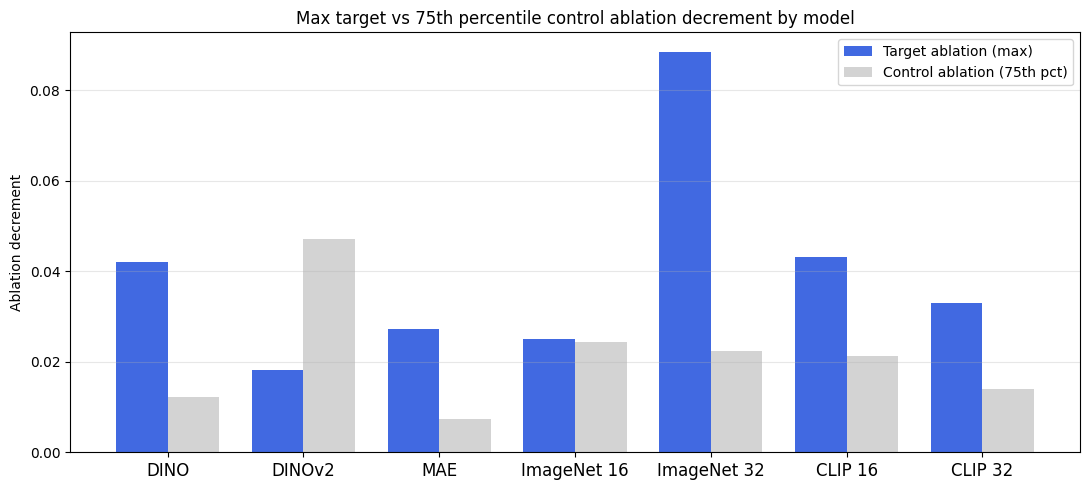

In [10]:
# Plot 4: Max target vs max control ablation decrement by model
fig = plot_max_ablation_decrement_bar(data=data)
plt.show()
fig.savefig(
    "../../figs/ablation.pdf",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.1,
    transparent=True,  # no background fill
    format="pdf"
)

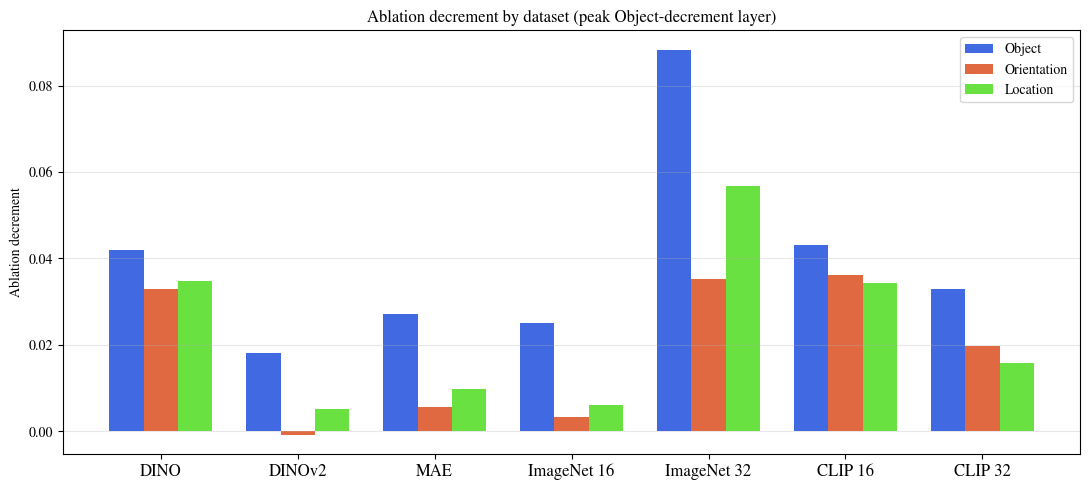

In [10]:
# Plot: Ablation decrement on Object, Orientation, and Location datasets (at peak Object-decrement layer)
fig = plot_ablation_decrement_by_dataset(data=data)
plt.show()

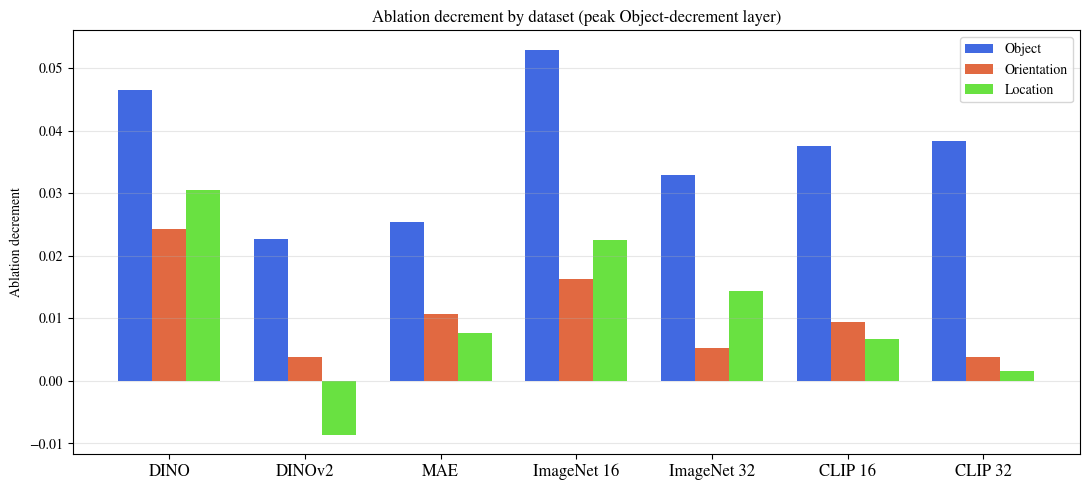

In [11]:
fig = plot_ablation_decrement_by_dataset(data=curves_data)
plt.show()

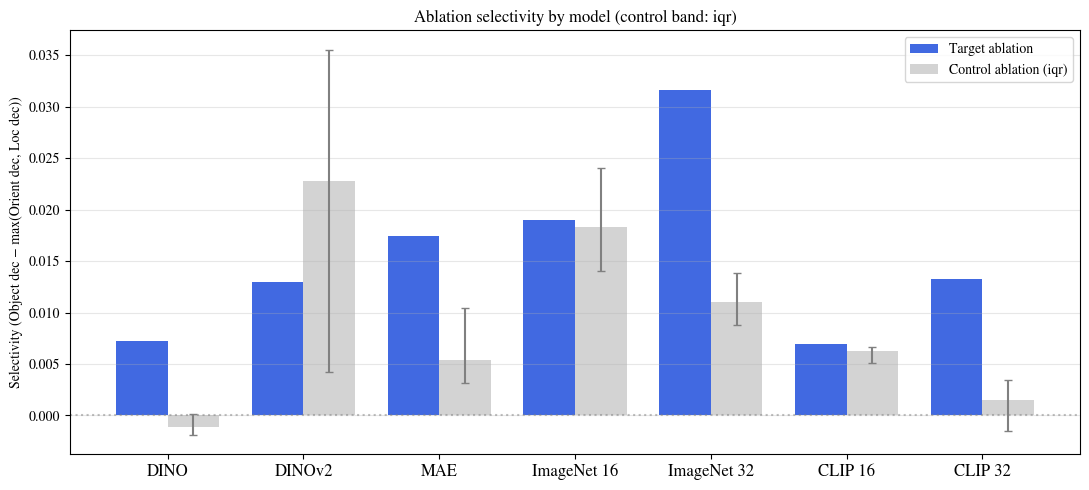

In [13]:
# Plot: Ablation selectivity (Object dec − max(Orient dec, Loc dec)) — target vs controls
# control_band: "iqr", "minmax", or "std"
fig = plot_ablation_selectivity_bar(data=data, control_band="iqr")
plt.show()

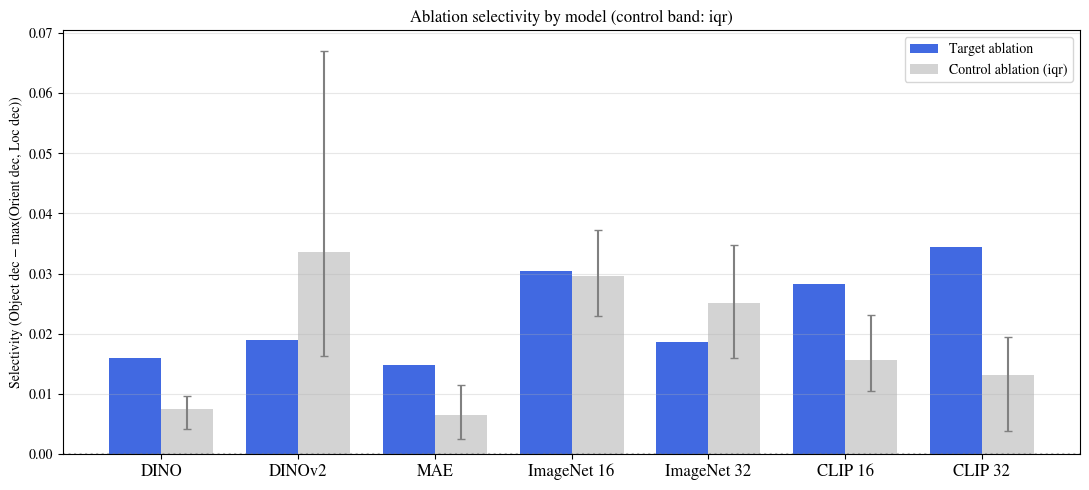

In [15]:
fig = plot_ablation_selectivity_bar(data=curves_data, control_band="iqr")
plt.show()

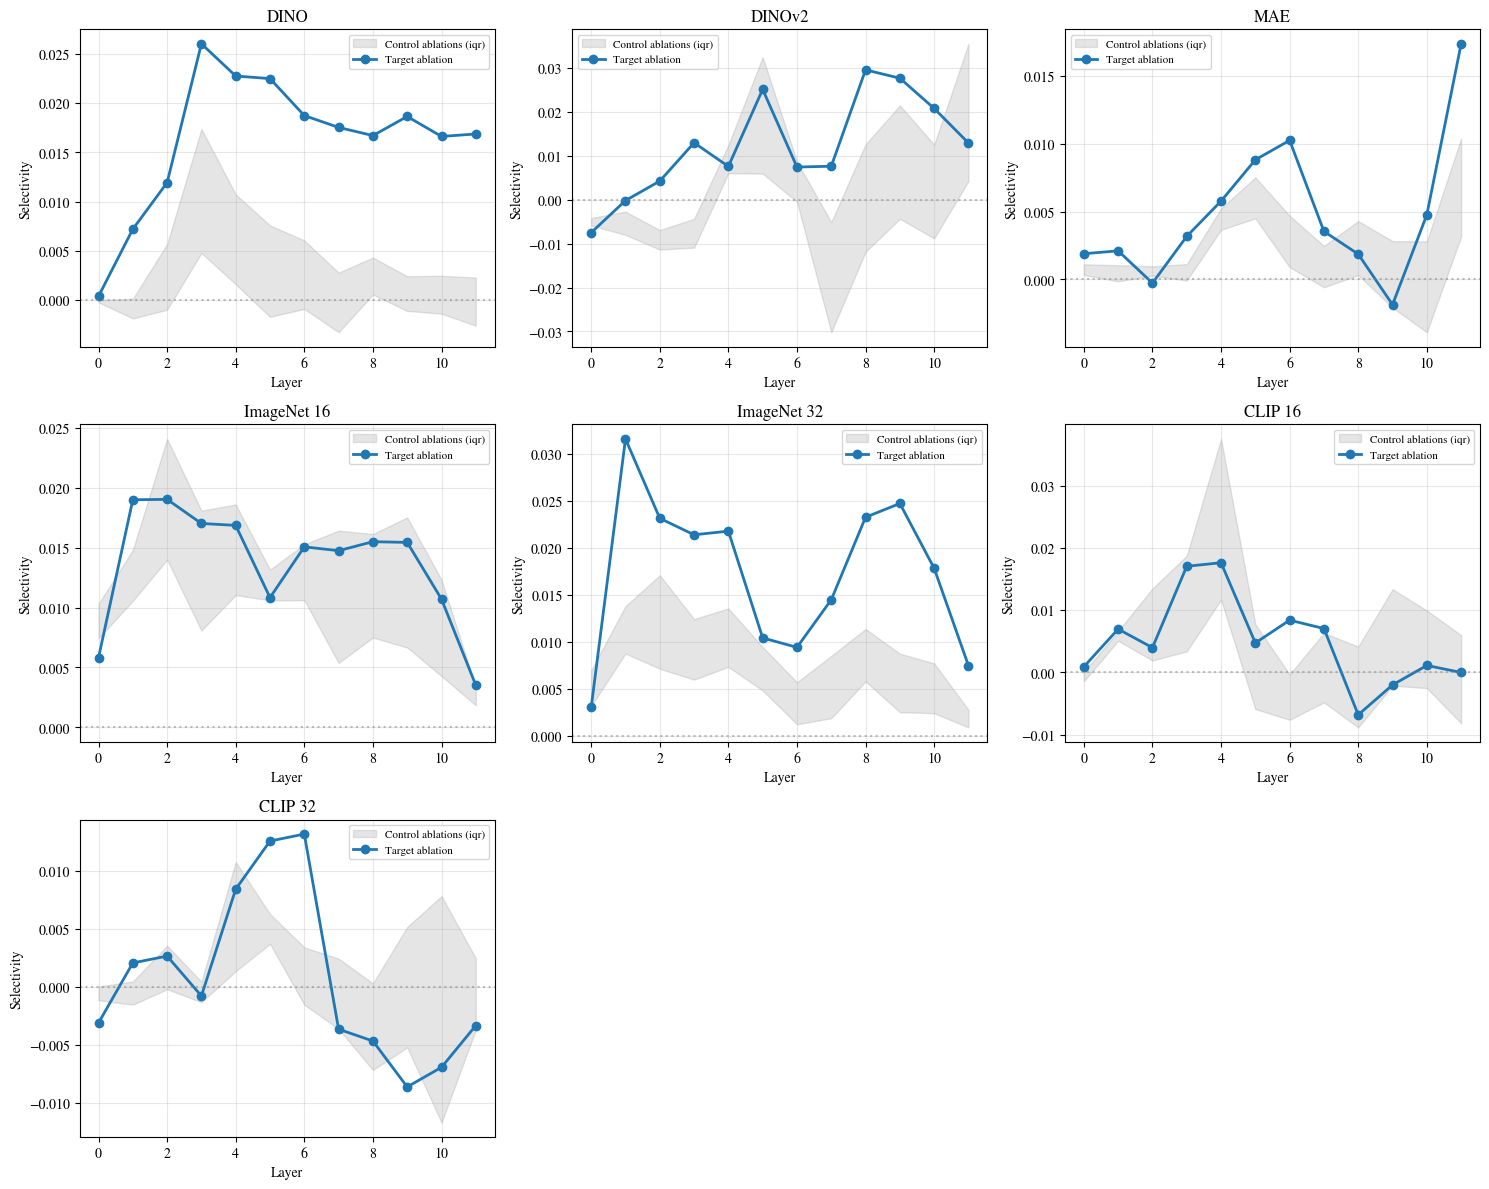

In [16]:
# Plot: Ablation selectivity by layer (one subplot per model, like plot_ablation_decrement_by_layer)
# control_band: "iqr", "minmax", or "std"
plot_ablation_selectivity_by_layer(data=data, control_band="iqr")
plt.show()

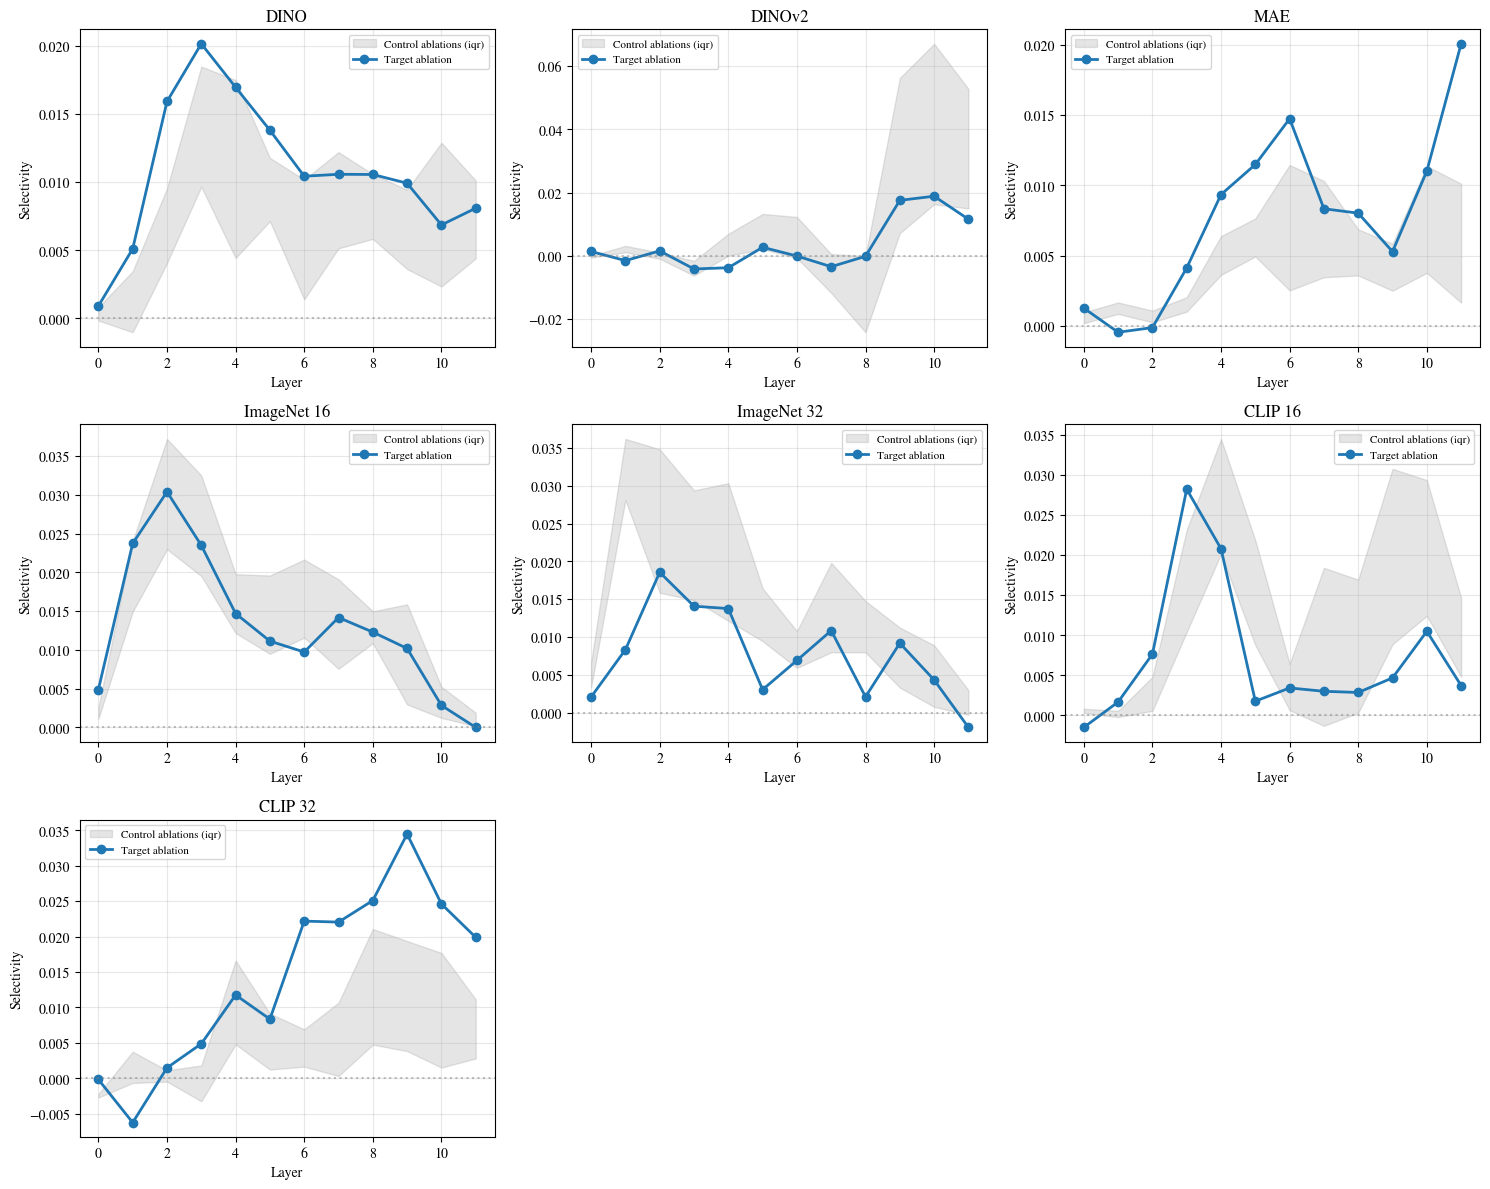

In [17]:
plot_ablation_selectivity_by_layer(data=curves_data, control_band="iqr")
plt.show()